# Barley spike trait extraction from UNet-predicted CT stacks (Ling et al. 2023)

**Paper:** Y. Ling, Q. Zhao, W. Liu, et al., *Detection and characterization of spike architecture
based on deep learning and X-ray computed tomography in barley*, Plant Methods **19**:115 (2023)
(preprint rs-2925483/v1). DOI: [10.1186/s13007-023-01096-w](https://doi.org/10.1186/s13007-023-01096-w)

**Author code:** `zerosky010/CT_barley_spike_detection` @ commit `5f5e72d129e8d8cd45a592ba81b5dc2ad513d9c4`
(pinned; all files are Git LFS objects, sha256-verified after download).

## Scope (one minimal example)

This notebook reproduces **one stage** of the paper pipeline: the point-cloud trait extraction
(`Scripts/Extraction.py`) applied to **one author-predicted UNet mask stack**
(`predicted_nii/1721_Unet_predicted_model3_mask3_stacked.nii`, variety **s28829**). It outputs
grain count, spike length, per-grain volume / surface area / length / width / thickness,
exactly as the author's script computes them. The UNet segmentation stage itself is **out of
scope**: the trained checkpoint `best_model_spike_ccd3_1.pth` is not present in the repository.

**Execution status:** CPU-only. No GPU is used anywhere in this extraction path (OpenCV
watershed, NumPy, Open3D CPU point-cloud operations). Select **Runtime > Change runtime type >
CPU** (a GPU is unnecessary).

**日本語概要:** このノートブックは論文パイプラインのうち、UNet予測マスク（`predicted_nii`）から
穂長・粒数・粒体積・粒表面積などを抽出する `Scripts/Extraction.py` の処理を、著者提供の予測結果
1サンプル（品種 s28829, ID 1721）で再現します。GPUは不要（CPUランタイムで実行）です。UNetの
学習・推論段階はチェックポイントが公開されていないため対象外です。

**AI-assisted adaptation notice (EN/JA):** The author's `Extraction.py` is downloaded from the
pinned commit and executed with **minimal, documented patches** (path handling and one
version-robust voxel-count form); all numerical operations are preserved. 本ノートブックは著者の
コードを最小限の修正（パス処理とボクセル数取得の頑健化）でそのまま実行します。数値処理は
変更していません。

## Runtime, expected duration and downloads

- **Runtime:** CPU (standard Colab). Measured on validation: see the report; expect roughly
  10–20 minutes end-to-end including ~55 MB of downloads and `pip install open3d`.
- **Downloads (all from the pinned commit's Git LFS media URLs, sha256-verified):**
  author `Extraction.py` (8.3 KB), predicted mask NII for variety 1721 (51.9 MB),
  author's extraction result point cloud `1721_newtest.pcd` (4.7 MB) and virtual-spike
  visualization `1721.png` (20 KB).
- **Limitations:** one example is not a reproduction of the paper's dataset-level statistics;
  the per-variety calibration (pixel size, DBSCAN `eps`) comes from the paper's
  Supplementary Table S1; the repository has no LICENSE file (reuse terms unclear).

**日本語:** CPUランタイム推奨。所要時間は検証時におよそ10–20分（ダウンロード約55 MB含む）。
サンプルは1品種のみであり、論文のデータセット全体の統計再現ではありません。較正値
（ピクセルサイズ・eps）は論文補足 Table S1 に基づきます。

### 1. Environment setup

**Purpose:** install the three third-party packages the author script needs that are not in
Colab's base image: `open3d` (point-cloud DBSCAN, voxel grid, alpha shapes), `nibabel` (NII
reader) and, only if missing, a headless OpenCV. NumPy / pandas / matplotlib are preinstalled.
**Expected result:** a short pip log; then the next cell prints versions.

**日本語:** 著者スクリプトが必要とする `open3d`・`nibabel`（と、無い場合のみ OpenCV）を
インストールします。NumPy/pandas/matplotlib はColab標準のものを使用します。

In [ ]:
import importlib.util, subprocess, sys

missing = [p for p in ("open3d", "nibabel") if importlib.util.find_spec(p) is None]
if importlib.util.find_spec("cv2") is None:
    missing.append("opencv-python-headless")
if missing:
    print("Installing:", missing, flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "--timeout", "120", *missing])
else:
    print("All required packages already present.")

Installing: ['open3d']


### 2. Imports and runtime check

**Purpose:** import the scientific stack used by `Extraction.py` (same imports as the author's
lines 1–8) and record the actual environment versions for the report. **Expected result:** a
version table; open3d will be a current release (the author used 0.16.0, which has no wheel
for Colab's Python; all API calls used here are stable across these versions).

**日本語:** `Extraction.py` と同じライブラリをimportsし、実行環境のバージョンを記録します。

In [ ]:
import os, time, statistics
import numpy as np
import pandas as pd
import nibabel as nib
import cv2
import matplotlib.pyplot as plt
import open3d as o3d

print("python:", __import__("sys").version.split()[0])
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("nibabel:", nib.__version__)
print("opencv:", cv2.__version__)
print("open3d:", o3d.__version__)

python: 3.13.18
numpy: 2.1.3
pandas: 2.2.3
nibabel: 5.4.2
opencv: 4.14.0
open3d: 0.20.0


### 3. Download the pinned author code and data (Git LFS payloads, sha256-verified)

**Purpose:** fetch exactly four files from the pinned commit
`5f5e72d129e8d8cd45a592ba81b5dc2ad513d9c4` of `zerosky010/CT_barley_spike_detection` via its
public Git LFS media URLs. Every file's SHA-256 is checked against the OID recorded in its Git
LFS pointer (metadata read from the GitHub contents API); a mismatch aborts the run.
The data files are the **author's own predicted mask for variety 1721** (the calibration row of
Supplementary Table S1: s28829, 84.999103 µm, eps 3), the author's extraction result point
cloud, and the author's virtual-spike visualization — all stay under `/content`.

**Expected result:** four `OK` lines with sizes.

**日本語:** ピン留めしたコミットから著者コード1件とデータ3件（LFS実体）をダウンロードし、
各ファイルのSHA-256をGit LFSポインタに記録されたOIDと照合します。データはすべて
`/content` 配下に置きます。

In [ ]:
from urllib.parse import quote
import hashlib, urllib.request

COMMIT = "5f5e72d129e8d8cd45a592ba81b5dc2ad513d9c4"
BASE = f"https://media.githubusercontent.com/media/zerosky010/CT_barley_spike_detection/{COMMIT}"

FILES = {  # repo path -> (local path, expected sha256 of LFS payload)
    "Scripts/Extraction.py": ("/content/Extraction.py",
        "cd96e5195a7db479293f807eb320c1b7ccc6955257c08a0e4e84d1a63b930a7d"),
    "predicted_nii/1721_Unet_predicted_model3_mask3_stacked.nii":
        ("/content/1721_Unet_predicted_model3_mask3_stacked.nii",
        "adcb1daae523eefe05cc5f754eb3d357df74ec7655b84108e832e4294e4a114c"),
    "results_pcd/1721_newtest.pcd": ("/content/1721_newtest.pcd",
        "d562c26ce863b044c94db03b7ab98992ec2b17dfa85fe9fbf6ba80cd95d80ca7"),
    "results_virtual spikes/1721.png": ("/content/1721_virtual_spike.png",
        "1ea75adceabb7cb5da37413f3c9647269c0a89fc39ba722e8fe000f5971e7b54"),
}

def fetch_lfs(repo_path, dest, expected_sha):
    url = f"{BASE}/{quote(repo_path)}"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=300) as r, open(dest, "wb") as f:
                h = hashlib.sha256()
                while True:
                    chunk = r.read(1 << 20)
                    if not chunk:
                        break
                    f.write(chunk)
                    h.update(chunk)
            break
        except Exception as e:
            if attempt == 2:
                raise RuntimeError(f"download failed after 3 attempts: {repo_path}: {e}")
            print(f"retry {attempt + 1} for {repo_path}: {e}", flush=True)
    if h.hexdigest() != expected_sha:
        raise RuntimeError(f"sha256 mismatch for {repo_path}")
    print(f"OK  {repo_path}  {os.path.getsize(dest):,} bytes  sha256 verified")

for repo_path, (dest, sha) in FILES.items():
    fetch_lfs(repo_path, dest, sha)

OK  Scripts/Extraction.py  8,258 bytes  sha256 verified


OK  predicted_nii/1721_Unet_predicted_model3_mask3_stacked.nii  51,940,512 bytes  sha256 verified


OK  results_pcd/1721_newtest.pcd  4,661,993 bytes  sha256 verified


OK  results_virtual spikes/1721.png  20,452 bytes  sha256 verified


### 4. Input preview — the predicted mask stack

**Purpose:** verify the downloaded NII and show what the extraction consumes: transverse
mid-slices of the author's UNet-predicted spike mask (binary: 0 background / non-zero spike).
The array is read per-slice through the Nibabel data proxy to keep memory low. Shape, dtype
and value counts are printed from the actual file. **Expected result:** three PNG panels of
white spike regions on black background (this is the model-predicted mask, i.e. the input to
trait extraction — not a raw CT image).

**日本語:** ダウンロードしたNII（著者のUNet予測マスク）の形状・dtype・値を確認し、断面の
中央3枚を表示します。白い領域がUNetが「穂」と予測したマスクです。

shape (x, y, slices): (232, 232, 965) | on-disk dtype: uint8
sampled voxels: 2,745,024 | value 0: 2,666,570 | value 255: 72,716 | other intermediate values: 5,738 (the released prediction is not strictly binary; watershed handles grayscale input)


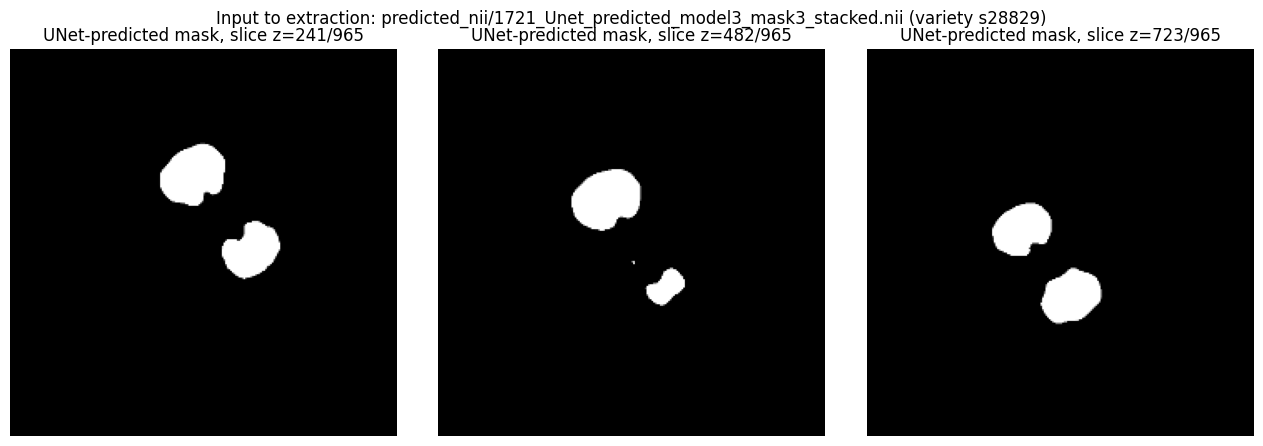

In [ ]:
NII_PATH = "/content/1721_Unet_predicted_model3_mask3_stacked.nii"

img = nib.load(NII_PATH)
print("shape (x, y, slices):", img.shape, "| on-disk dtype:", img.get_data_dtype())

vals, counts = np.unique(np.asarray(img.dataobj[:, :, :: max(1, img.shape[2] // 50)]), return_counts=True)
n_zero = int(counts[vals == 0][0])
n_255 = int(counts[vals == 255][0])
print(f"sampled voxels: {int(counts.sum()):,} | value 0: {n_zero:,} | value 255: {n_255:,} | "
      f"other intermediate values: {int(counts.sum() - n_zero - n_255):,} "
      f"(the released prediction is not strictly binary; watershed handles grayscale input)")

mids = [img.shape[2] // 4, img.shape[2] // 2, 3 * img.shape[2] // 4]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, z in zip(axes, mids):
    ax.imshow(np.asarray(img.dataobj[:, :, z]).T, cmap="gray", origin="lower")
    ax.set_title(f"UNet-predicted mask, slice z={z}/{img.shape[2]}")
    ax.axis("off")
fig.suptitle("Input to extraction: predicted_nii/1721_Unet_predicted_model3_mask3_stacked.nii (variety s28829)")
plt.tight_layout()
plt.savefig("/content/input_mask_preview.png", dpi=110)
plt.show()

### 5. Author reference outputs for the same variety

**Purpose:** show the author's published extraction visualization for variety 1721
(`results_virtual spikes/1721.png`, their pipeline output — displayed as **reference material**,
not our result) and load their result point cloud `1721_newtest.pcd`, reporting its point
count and axis extents for a later plausibility check. **Expected result:** the reference PNG
plus printed PCD statistics; the PCD's internal coordinate convention is discovered here at
runtime and interpreted in the comparison cell below.

**日本語:** 同一サンプル（1721）に対する著者の可視化画像と抽出結果点群を読み込み、後の
整合性確認のために点数と各軸の範囲を表示します。画像は著者の成果物であり、本ノートブックの
実行結果ではありません。

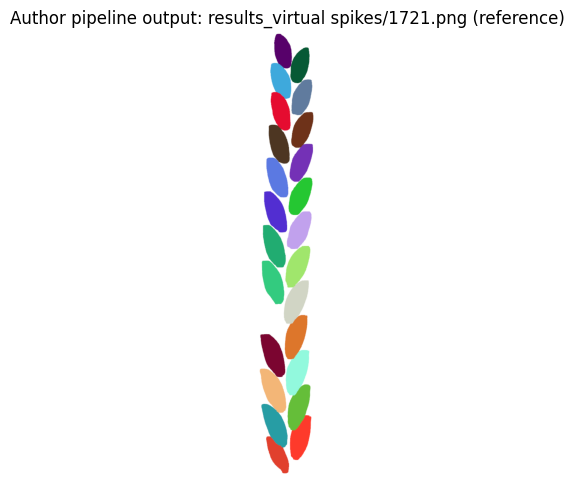

author PCD points: 171025
author PCD per-axis min: [ 2. 74. 54.]
author PCD per-axis max: [939. 168. 186.]
author PCD extent (max-min): [937.  94. 132.]
author PCD distinct colors (cluster labels): 24


In [ ]:
plt.figure(figsize=(5, 5))
plt.imshow(plt.imread("/content/1721_virtual_spike.png"))
plt.axis("off")
plt.title("Author pipeline output: results_virtual spikes/1721.png (reference)")
plt.tight_layout()
plt.savefig("/content/author_reference_1721.png", dpi=110)
plt.show()

ref_pcd = o3d.io.read_point_cloud("/content/1721_newtest.pcd")
ref_pts = np.asarray(ref_pcd.points)
print("author PCD points:", ref_pts.shape[0])
print("author PCD per-axis min:", ref_pts.min(axis=0).round(2))
print("author PCD per-axis max:", ref_pts.max(axis=0).round(2))
print("author PCD extent (max-min):", (ref_pts.max(axis=0) - ref_pts.min(axis=0)).round(2))
if ref_pcd.has_colors():
    ref_colors = np.asarray(ref_pcd.colors)
    print("author PCD distinct colors (cluster labels):", len(np.unique(ref_colors, axis=0)))

### 6. Apply the minimal documented patches to `Extraction.py`

**Purpose:** the author's script hardcodes their Windows drive (`G:\lingyimin_wheat\...`,
`niipath.split('\\')[4]`, `r".\99results\..."`) and counts voxels through a repr-string
parsing trick. We apply five **behavior-preserving** patches, each asserted to match exactly:

1. robust sample-ID parsing from any OS path (`os.path.basename`, replaces the `split('\\')[4]`
   index into a Windows path; same resulting integer, e.g. `1721`);
2. output directory `./99results/` with forward slashes + `os.makedirs` (same file names as the
   author's main block, lines 198–201);
3. `niiimg=np.asanyarray(niimodel.dataobj)` instead of `get_fdata()` — identical values (the
   author immediately casts every slice to `uint8` at line 26) with 4× less peak memory;
4. voxel count via `len(voxel_grid.get_voxels())` — the same count the author obtains from
   `int(str(voxel_grid.get_voxels).split(' ')[-2])`, without depending on repr formatting;
5. the module-level file-discovery block (lines 191–211, which reads the missing
   `U-net predicted data.xlsx` and iterates `G:\...`) is removed — we call `extract()` directly.

**Expected result:** `5 patches applied` and the patched file written to `/content/`.

**日本語:** 著者スクリプトのWindows依存パス処理と、表現形式に依存するボクセル数取得を、
挙動を変えない5箇所の修正のみで置き換えます（各置換は1回だけマッチすることを表明）。
数値演算はすべて元のままです。

In [ ]:
src = open("/content/Extraction.py", encoding="utf-8").read()

BSP = chr(92)  # single backslash character, kept explicit to avoid escaping mistakes

patches = [
    # 1) OS-independent sample-ID parse (was: index [4] into a Windows path)
    ("idname=int(niipath.split('" + BSP + BSP + "')[4].split('_')[0])",
     "idname=int(os.path.basename(niipath).split('_')[0])"),
    # 2) forward-slash result paths (author used r".<BSP>99results<BSP>..." twice)
    ("." + BSP + "99results" + BSP, "./99results/"),
    # 3) memory-lean, value-identical array read (author casts to uint8 anyway)
    ("niiimg=niimodel.get_fdata()",
     "niiimg=np.asanyarray(niimodel.dataobj)"),
    # 4) version-robust voxel count (same integer as the repr-string hack)
    ("int(str(voxel_grid.get_voxels).split(' ')[-2])",
     "len(voxel_grid.get_voxels())"),
]
for old, new in patches:
    n = src.count(old)
    assert n >= 1, f"patch source not found: {old!r}"
    src = src.replace(old, new)
    print(f"patched {n} occurrence(s): {old[:52]}")

# 5) drop the author's module-level xlsx/Windows-drive discovery block; we drive extract() ourselves
marker = "# Input files"
assert src.count(marker) == 1
src = src[:src.index(marker)]
src = "import os\nos.makedirs('./99results', exist_ok=True)\n\n" + src

open("/content/extraction_author.py", "w", encoding="utf-8").write(src)
import ast
ast.parse(src)
print("patched script written and syntax-checked: /content/extraction_author.py")

patched 1 occurrence(s): idname=int(niipath.split('\\')[4].split('_')[0])
patched 2 occurrence(s): .\99results\
patched 1 occurrence(s): niiimg=niimodel.get_fdata()
patched 1 occurrence(s): int(str(voxel_grid.get_voxels).split(' ')[-2])
patched script written and syntax-checked: /content/extraction_author.py


### 7. Replicate the author's output-file headers, then run the extraction

**Purpose:** the author's main block (lines 198–204) writes the two TSV headers before calling
`extract()`; we replicate those exact header strings, then import the patched module and run
`extract()` once on the s28829 stack with its **Supplementary Table S1 calibration**
(`image_Pixels_size_um=84.999103`, `eps=3` → `min_points=89`, the author's own eps=3 branch).
Per-slice watershed → 3D point cloud → DBSCAN → per-grain OBB/voxel/alpha-shape metrics;
`extract()` prints its progress and appends results to `./99results/`. **Expected result:**
progress output, then the returned `(grain clusters, spike length mm, avg grain volume mm³,
avg surface mm²)` tuple and wall time (DBSCAN and alpha shapes dominate; several minutes on CPU
is normal).

**日本語:** 著者のメインブロックと同じヘッダを書き込み、補足 Table S1 の s28829 用較正値
（84.999103 µm, eps=3）で `extract()` を1回実行します。DBSCANとαシェープが時間の大部分で、
CPUで数分かかることがあります。

In [ ]:
import importlib.util
spec = importlib.util.spec_from_file_location("extraction_author", "/content/extraction_author.py")
extraction_author = importlib.util.module_from_spec(spec)
spec.loader.exec_module(extraction_author)

HEAD_MAIN = ("ID\tpixel_size(um)\teps\tspike_length(mm)\tgrain_sum\tsum_volume(mm3)\t"
             "average_surface_area(mm2)\taverage_grain_length(mm)\taverage_grain_width(mm)\t"
             "average_grain_thickness(mm)\n")
HEAD_DETAIL = "ID\tgrain_ID\tvolume(mm3)\tsurface_area(mm2)\tgrain_length(mm)\tgrain_width(mm)\tgrain_thickness(mm)\n"
os.makedirs("./99results", exist_ok=True)  # same directory the patched script writes into
open("./99results/MorphoExtract_output_extract_morphological_barley.txt", "w").write(HEAD_MAIN)
open("./99results/MorphoExtract_output_grain_detail_data.txt", "w").write(HEAD_DETAIL)

t0 = time.time()
result = extraction_author.extract(
    niipath=NII_PATH,
    image_Pixels_size_um=84.999103,  # Supplementary Table S1: s28829
    eps=3,                           # Supplementary Table S1: s28829 -> author's eps==3 branch (min_points=89)
)
print(f"\nextract() returned {result} in {time.time() - t0:.1f} s")

1721 :



Stacked image shape: (965, 232, 232, 3)
Stacked marker shape: (965, 232, 232)


Max_marker_value= 5


Stacked marker xyz location shape:(1481161, 3),dtype:float64
Stacked marker xyz bounding-location shape:(177989, 3),dtype:float64


All picture data transformed into point cloud data, Starting Cluster-Dbscan


pixels_size(um):84.999103


... (13 outputs left out)

[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh

[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh

[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh

[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh
[Open3D WARNING] [CreateFromPointCloudAlphaShape] invalid tetra in TetraMesh

### 8. Parse the extraction outputs into tables

**Purpose:** read the two files the author's pipeline produces (same names and tab-separated
schema as lines 198–199) and display them: one summary row (spike length, grain count, summed
and average volumes, average surface area, average grain L/W/T) and the per-grain table, also
exported as CSV for download. **Expected result:** two DataFrames; note that the function's
`return` value repeats the cluster count with an off-by-one (`max_label` is reassigned before
`return`, line 119 vs 189), so the tables parsed from the files — which the author's own
pipeline reports — are used as the authoritative results.

**日本語:** `extract()` が出力した2つのTSV（著者パイプラインと同一スキーマ）を読み込み、
要約行と粒ごとの表を表示します（CSVとしても保存）。関数の戻り値には著者コード由来の
オフバイワンがあるため、ファイルから読んだ値を正とします。

In [ ]:
df_main = pd.read_csv("./99results/MorphoExtract_output_extract_morphological_barley.txt", sep="\t")
df_detail = pd.read_csv("./99results/MorphoExtract_output_grain_detail_data.txt", sep="\t")

print("Summary (s28829 / ID 1721):")
display(df_main)
print(f"\nPer-grain table: {len(df_detail)} grains")
display(df_detail.head(15))

df_detail.to_csv("./99results/p0736_grain_detail.csv", index=False)
df_main.to_csv("./99results/p0736_trait_summary.csv", index=False)
print("CSV exported: ./99results/p0736_trait_summary.csv, ./99results/p0736_grain_detail.csv")

Summary (s28829 / ID 1721):


,ID,pixel_size(um),eps,spike_length(mm),grain_sum,sum_volume(mm3),average_surface_area(mm2),average_grain_length(mm),average_grain_width(mm),average_grain_thickness(mm)
0,1721,84.999103,3,79.899157,24,1018.698565,179.45782,7.539792,3.728373,2.911733



Per-grain table: 24 grains


,ID,grain_ID,volume(mm3),surface_area(mm2),grain_length(mm),grain_width(mm),grain_thickness(mm)
0,1721,1721_001,25.201664,102.726947,7.128732,2.942939,2.410318
1,1721,1721_002,43.355238,190.832600,8.017626,3.619871,2.933408
2,1721,1721_003,47.225331,197.133136,8.408378,3.779740,2.924497
3,1721,1721_004,48.981673,204.811830,8.321314,3.888927,2.965941
4,1721,1721_005,51.908500,208.393857,8.452427,3.936286,3.051330
5,1721,1721_006,52.973974,216.203650,8.541632,3.979709,3.090528
6,1721,1721_007,50.702397,209.256906,8.232978,3.975037,3.125621
7,1721,1721_008,49.176345,203.203330,8.399634,3.854137,2.971106
8,1721,1721_009,47.791537,197.428036,8.480628,3.810110,2.928954
9,1721,1721_010,49.580426,205.913924,8.350016,3.969329,3.064304


CSV exported: ./99results/p0736_trait_summary.csv, ./99results/p0736_grain_detail.csv


### 9. Per-grain result graphs (created for this notebook)

**Purpose:** visualize the per-grain distributions the extraction produced: grain volume and
surface-area histograms plus volume-vs-surface scatter, all computed from the table above.
These graphs are **additional visualizations created for this notebook**, not author figures.
**Expected result:** one PNG with three panels; units mm³ / mm².

**日本語:** 抽出結果の粒体積・表面積の分布を可視化します（本ノートブックで追加作成した
図であり、論文の図ではありません）。

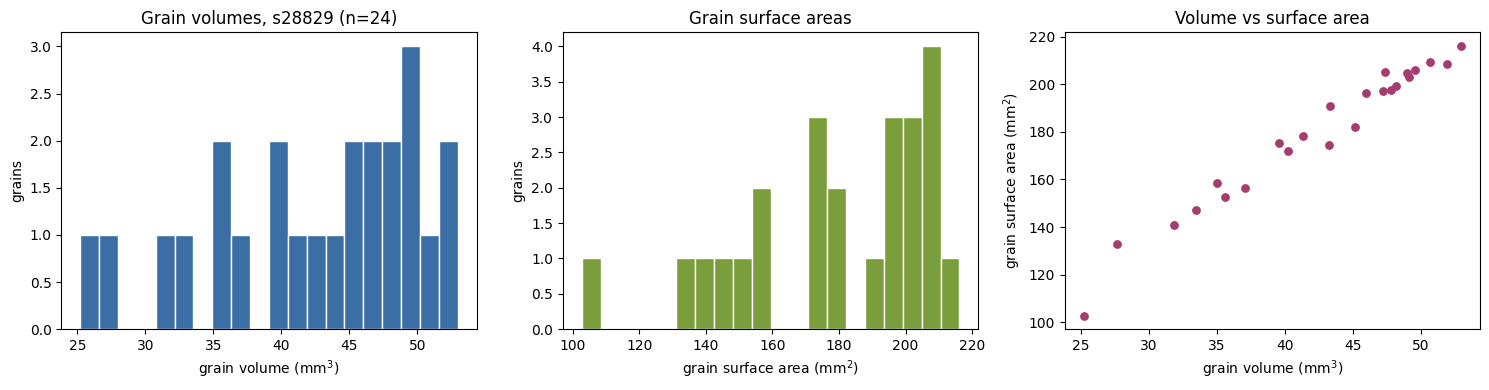

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df_detail["volume(mm3)"], bins=20, color="#3b6ea5", edgecolor="white")
axes[0].set_xlabel("grain volume (mm$^3$)")
axes[0].set_ylabel("grains")
axes[0].set_title(f"Grain volumes, s28829 (n={len(df_detail)})")

axes[1].hist(df_detail["surface_area(mm2)"], bins=20, color="#7a9e3b", edgecolor="white")
axes[1].set_xlabel("grain surface area (mm$^2$)")
axes[1].set_ylabel("grains")
axes[1].set_title("Grain surface areas")

axes[2].scatter(df_detail["volume(mm3)"], df_detail["surface_area(mm2)"], s=28, color="#a53b6e")
axes[2].set_xlabel("grain volume (mm$^3$)")
axes[2].set_ylabel("grain surface area (mm$^2$)")
axes[2].set_title("Volume vs surface area")

plt.tight_layout()
plt.savefig("/content/grain_distributions.png", dpi=110)
plt.show()

### 10. Plausibility checks against author reference values

**Purpose:** three sanity comparisons for this single example, printed side by side:
(1) our spike length / grain volume / surface area / grain L·W·T against the paper's
Supplementary Table S2 **Landrace** group means (s28829 is a landrace; a single spike is
expected to deviate from a group mean — plausibility check, not validation of published
statistics);
(2) the bounding-extent of the author's result point cloud along its **stack axis (axis 0)** —
the convention observed at runtime in the reference PCD — times the pixel size, against our
spike length (the author's `extract()` measures length along the same stack axis);
(3) our grain count against the number of distinct cluster colors in the author's PCD
(the author colors one DBSCAN cluster per grain; noise is black).
**Expected result:** values of the same order as the reference ranges.

**日本語:** 論文補足 Table S2 の Landrace 群平均、著者の結果点群のスタック軸（axis 0）範囲、
および著者点群のクラスタ色数と、本実行結果を比較します。単一サンプルと群平均の比較であり、
妥当性確認の参考値です。

In [ ]:
# Supplementary Table S2, Landrace column (mean ± sd), from SupplementaryMaterials.docx
landrace_ref = {"Spike length (mm)": (86.0, 6.1), "Grain volume (mm3)": (41.2, 6.5),
                "Grain surface area (mm2)": (170.3, 24.7), "Grain length (mm)": (7.2, 0.8),
                "Grain width (mm)": (3.8, 0.2), "Grain thickness (mm)": (2.9, 0.1)}
ours = {"Spike length (mm)": float(df_main["spike_length(mm)"].iloc[0]),
        "Grain volume (mm3)": float(df_main["sum_volume(mm3)"].iloc[0] / df_main["grain_sum"].iloc[0]),
        "Grain surface area (mm2)": float(df_main["average_surface_area(mm2)"].iloc[0]),
        "Grain length (mm)": float(df_main["average_grain_length(mm)"].iloc[0]),
        "Grain width (mm)": float(df_main["average_grain_width(mm)"].iloc[0]),
        "Grain thickness (mm)": float(df_main["average_grain_thickness(mm)"].iloc[0])}
print(f"{'trait':28s} {'this run (single spike s28829)':>30s} {'Table S2 Landrace mean ± sd':>30s}")
for k in ours:
    m, s = landrace_ref[k]
    print(f"{k:28s} {ours[k]:>30.2f} {f'{m} ± {s}':>30s}")
grain_count = int(df_main["grain_sum"].iloc[0])
print(f"grain count (this run): {grain_count}")

ext_voxels = float(ref_pts[:, 0].max() - ref_pts[:, 0].min())
ext_mm = ext_voxels * 84.999103 / 1000
print(f"\nauthor PCD stack-axis (0) extent = {ext_voxels:.0f} voxels x 84.999103 um = {ext_mm:.2f} mm "
      f"vs our spike length {ours['Spike length (mm)']:.2f} mm")
if ref_pcd.has_colors():
    n_author_clusters = len(np.unique(np.asarray(ref_pcd.colors), axis=0))
    print(f"author PCD distinct colors (clusters incl. black noise): {n_author_clusters} vs our grain count {grain_count}")

trait                        this run (single spike s28829)    Table S2 Landrace mean ± sd
Spike length (mm)                                     79.90                     86.0 ± 6.1
Grain volume (mm3)                                    42.45                     41.2 ± 6.5
Grain surface area (mm2)                             179.46                   170.3 ± 24.7
Grain length (mm)                                      7.54                      7.2 ± 0.8
Grain width (mm)                                       3.73                      3.8 ± 0.2
Grain thickness (mm)                                   2.91                      2.9 ± 0.1
grain count (this run): 24

author PCD stack-axis (0) extent = 937 voxels x 84.999103 um = 79.64 mm vs our spike length 79.90 mm
author PCD distinct colors (clusters incl. black noise): 24 vs our grain count 24


## Interpretation and limitations

**What was executed:** the author's `Scripts/Extraction.py` (pinned commit, sha256-verified),
with five documented behavior-preserving patches, ran end-to-end on their predicted mask stack
for barley variety **s28829** (ID 1721) with the paper's own calibration from Supplementary
Table S1 (84.999103 µm; DBSCAN eps 3, min_points 89). Outputs: spike length, grain count,
per-grain volume (voxel counting), surface area (alpha shapes, α=12) and grain L/W/T —
the paper's Methods section "Extraction of plant phenotypic traits from image stacks"
confirms the same operations (watershed via OpenCV, DBSCAN via Open3D, alpha = 12, OBB-based
dimensions).

**What was NOT executed / not verified:** the UNet segmentation stage (training or inference —
the checkpoint `best_model_spike_ccd3_1.pth` is absent from the repository, so the input here is
the author's own released prediction); the remaining 10 varieties; validation against manual
measurements; the wild/landrace/cultivar comparisons. One example does not verify the paper's
dataset-level results. The repository has **no LICENSE file**; reuse beyond inspection is at
the learner's discretion. The function `extract()`'s `return` value contains an off-by-one in
the cluster count (author code, line 119/189); the parsed output files are authoritative.

**日本語:** 実行したのは、著者公開のUNet予測マスク（s28829）1サンプルに対する形質抽出段階です。
UNetの推論はチェックポイント未公開のため未実行であり、他10品種・手動計測との検証・群間比較も
対象外です。単一サンプルの実行は論文のデータセット水準の結果を検証するものではありません。
リポジトリにはLICENSEがありません。`extract()` の戻り値には著者コード由来の粒数の
オフバイワンがあり、出力ファイルの値を正としています。

## References

1. Y. Ling, Q. Zhao, W. Liu, Z. Li, X. Wang, S. Wang, J. Wang, R. Christopher, X. Zhao.
   *Detection and characterization of spike architecture based on deep learning and X-ray
   computed tomography in barley.* Plant Methods 19:115 (2023). DOI 10.1186/s13007-023-01096-w
   (preprint: Research Square rs-2925483/v1). Full text via Europe PMC PMC10604417.
2. Code: `zerosky010/CT_barley_spike_detection` @ `5f5e72d129e8d8cd45a592ba81b5dc2ad513d9c4`
   (`Scripts/Extraction.py`, `Scripts/requirements.txt`).
3. Supplementary Materials (Additional file 1), Tables S1–S2: per-variety pixel size / DBSCAN
   eps and trait summaries.
4. Data (this run): `predicted_nii/1721_Unet_predicted_model3_mask3_stacked.nii`,
   `results_pcd/1721_newtest.pcd`, `results_virtual spikes/1721.png` — Git LFS payloads of the
   pinned commit, sha256-verified on download.